# From Whisper to Voice: System Walkthrough
*DyNaVoiCeR II: real-time whispered-to-speech conversion by per-pulse LPC filtering*

The system takes **whispered speech** and puts the voice back in. A whisper still carries the vocal-tract shape (the formants), but it has no glottal excitation. So we:

1. **estimate the vocal tract** of every frame from the whisper (LPC through ODFT, Wiener–Khinchin and Levinson–Durbin),
2. **synthesise a glottal source** (LF pulses following an $F_0$ contour, mixed with noise), and
3. **filter each pulse individually** with an envelope interpolated between frames, then overlap-add the results.

![System diagram](figures/systemDiagram.png)

| § | Block | Thesis |
|---|-------|--------|
| 1 | Glottal source: LF model, harmonic/NRD synthesis, $F_0$ contour | Ch. 4 |
| 2 | Vocal-tract filter: ODFT, Wiener–Khinchin, Levinson–Durbin, DF-II IIR, spectral tilt, vowel synthesis | Ch. 5 |
| 3 | Overlap-add engine: frame filtering vs. per-pulse filtering | Ch. 6.1 |
| 4 | Segmentation: whisper activity detection, centre of gravity, sigmoid mapping | Ch. 6.2–6.3 |
| 5 | Complete system: the MUSHRA test conditions side by side | Ch. 6.4, 7 |

> Run top to bottom from `systemOverview/` (it reads `LFmag.mat` and `LFNRD.mat`, plus the recordings in `data/`). Figures are built from `figures/*.tikz` with `figures/build.sh`.

In [47]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import loadmat, wavfile

from IPython.display import Audio, display

# Global parameters (same as the STM32 implementation)
FS = 22050          # sampling frequency (Hz)
N = 1024            # analysis window = pulse buffer length
N2 = N // 2         # hop size = DMA buffer size (~23 ms)
NLPC = 22           # LPC filter order -> up to 11 formants
INT16_MAX = 32767

plt.rcParams.update(
    {'figure.figsize': (11, 3.5), 
     'font.size': 13,
     'axes.grid': True, 
     'grid.alpha': 0.3, 
     'figure.dpi': 110}
    )

def play(x, fs=FS, label=None):
    """Peak-normalised audio player, with an optional label above it."""
    if label:
        print(label)
    display(Audio(x / (np.max(np.abs(x)) + 1e-12), rate=fs, normalize=False))


def specshow(ax, x, fs=FS, fmax=8000, nfft=N, nperseg=N2):
    """Log-power spectrogram on a kHz axis."""
    f, t, S = signal.spectrogram(x, fs, window='hann', nperseg=nperseg,
                                 noverlap=3 * nperseg // 4, nfft=nfft)
    ax.pcolormesh(t, f / 1e3, 10 * np.log10(S + 1e-12), shading='auto', cmap='magma')
    ax.set_ylim(0, fmax / 1e3)
    ax.set_ylabel('Frequency (kHz)')
    ax.set_xlabel('Time (s)')
    ax.grid(False)

## 1 · Glottal source (Ch. 4)

### 1.1 The Liljencrants–Fant model

Voiced speech is excited by the **glottal flow derivative** (GFD). We use the LF model, ported from VOICEBOX `v_glotlf`, with its defaults $T_p = 0.48\,T_0$ and $T_e = 0.6\,T_0$:

$$
E(t) =
\begin{cases}
 E_0\, e^{a t} \sin(\omega_g t) & 0 \le t < T_e \quad \text{(open phase)}\\[2pt]
 -\dfrac{E_e}{\epsilon T_a}\left(e^{-\epsilon (t-T_e)} - e^{-\epsilon (T_0-T_e)}\right) & T_e \le t < T_0 \quad \text{(return phase)}
\end{cases}
$$

The sharp negative peak at $T_e$ (glottal closure) is what gives voiced speech its broadband energy.

### References

- [sap-voicebox](https://github.com/ImperialCollegeLondon/sap-voicebox) (Speech And Audio Processing Lab - Imperial College of London)

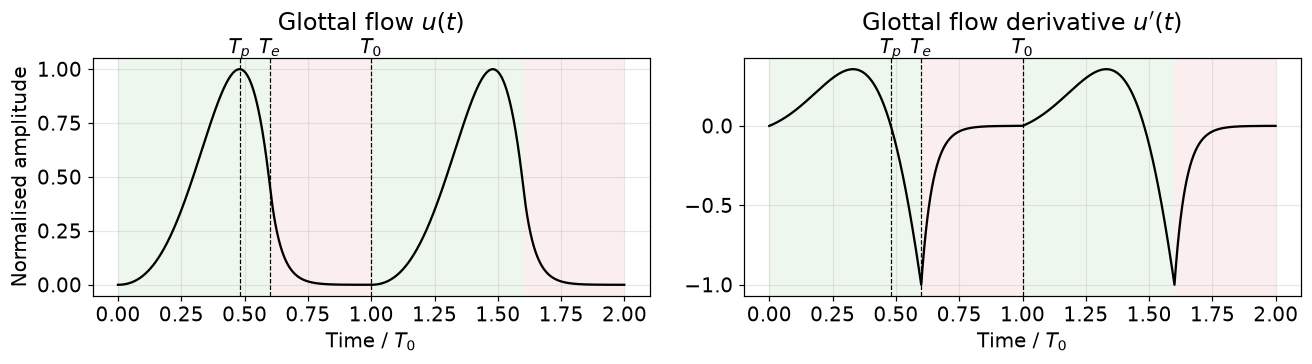

Raw LF pulse train @ 110 Hz (no vocal tract yet)


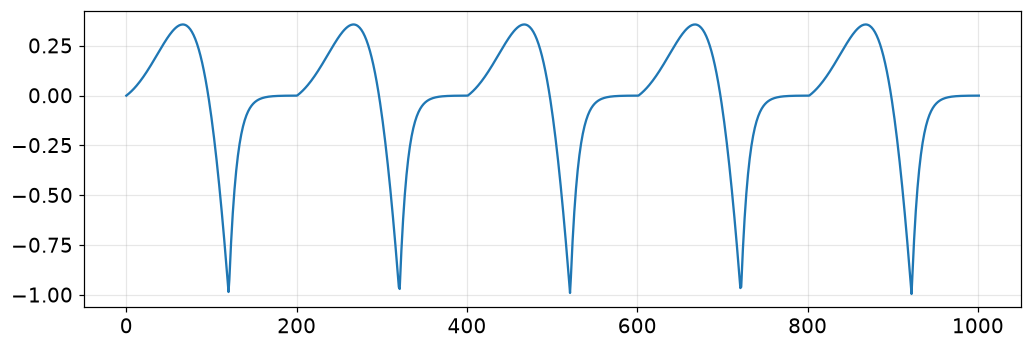

In [ ]:
def v_glotlf(d=0, t=None, p=None):
    """LF glottal flow (d=0) or its derivatives (d=1, 2); t in periods. Port of VOICEBOX v_glotlf."""
    default_p = np.array([0.6, 0.1, 0.2])
    p = default_p if p is None else np.concatenate([p, default_p[len(p):]])
    tt = np.linspace(0, 0.99, 100) if t is None else t - np.floor(t)

    te = p[0]
    mtc = te - 1
    e0 = 1
    wa = np.pi / (te * (1 - p[2]))
    a = -np.log(-p[1] * np.sin(wa * te)) / te
    inta = e0 * ((wa / np.tan(wa * te) - a) / p[1] + wa) / (a**2 + wa**2)

    rb0 = p[1] * inta
    rb = rb0
    for _ in range(4):  # Newton iterations for the return-phase time constant
        kk = 1 - np.exp(mtc / rb)
        err = rb + mtc * (1 / kk - 1) - rb0
        derr = 1 - (1 - kk) * (mtc / rb / kk)**2
        rb = rb - err / derr

    e1 = 1 / (p[1] * (1 - np.exp(mtc / rb)))
    ta = tt < te
    tb = ~ta
    u = np.zeros_like(tt)
    if d == 0:
        u[ta] = e0 * (np.exp(a * tt[ta]) * (a * np.sin(wa * tt[ta]) - wa * np.cos(wa * tt[ta])) + wa) / (a**2 + wa**2)
        u[tb] = e1 * (np.exp(mtc / rb) * (tt[tb] - 1 - rb) + np.exp((te - tt[tb]) / rb) * rb)
    elif d == 1:
        u[ta] = e0 * np.exp(a * tt[ta]) * np.sin(wa * tt[ta])
        u[tb] = e1 * (np.exp(mtc / rb) - np.exp((te - tt[tb]) / rb))
    elif d == 2:
        u[ta] = e0 * np.exp(a * tt[ta]) * (a * np.sin(wa * tt[ta]) + wa * np.cos(wa * tt[ta]))
        u[tb] = e1 * np.exp((te - tt[tb]) / rb) / rb
    else:
        raise ValueError('Derivative must be 0, 1, or 2')
    return u


tt = np.linspace(0, 2, 2000, endpoint=False)
fig, axs = plt.subplots(1, 2, figsize=(12, 3.5))
for ax, d, name in zip(axs, (0, 1), ('Glottal flow $u(t)$', "Glottal flow derivative $u'(t)$")):
    u = v_glotlf(d, tt)
    ax.plot(tt, u / np.max(np.abs(u)), color='k')
    for k in range(2):
        ax.axvspan(k, k + 0.6, color='tab:green', alpha=0.08, lw=0)
        ax.axvspan(k + 0.6, k + 1, color='tab:red', alpha=0.08, lw=0)
    for x, lab in ((0.48, '$T_p$'), (0.6, '$T_e$'), (1.0, '$T_0$')):
        ax.axvline(x, ls='--', color='k', lw=0.8)
        ax.text(x, 1.02, lab, transform=ax.get_xaxis_transform(), ha='center')
    ax.set_xlabel('Time / $T_0$')
    ax.set_title(name, pad=18)
axs[0].set_ylabel('Normalised amplitude')
plt.tight_layout()
plt.show()

f0_demo = 110   # average fundamental frequency of male speech is around 110 Hz
buzz = v_glotlf(1, np.arange(FS) * f0_demo / FS)
buzz = (buzz / max(abs(buzz)))
play(buzz, label=f'Raw LF pulse train @ {f0_demo} Hz (no vocal tract yet)')

plt.plot(buzz[0:5*FS//(f0_demo)])

### 1.2 (Sidenote) Harmonic synthesis with Normalised Relative Delays

The STM32 system we were using, cannot afford to evaluate the LF equations on per-sample basis, so each pulse can be as a **sum of harmonics** with measured magnitudes. The phases are stored as **NRDs**, i.e. each harmonic's phase relative to the fundamental:

$$
\text{NRD}_l = \frac{\phi_l - l\,\phi_1}{2\pi}, \qquad
g'(t) = \sum_{l=1}^{L} \text{Mag}_l \,\sin\!\left(2\pi l F_0 t + 2\pi\,\text{NRD}_l\right)
$$

The LF NRDs grow almost **linearly** with $l$, so a whole phase table collapses into **two coefficients**: $\text{NRD}_l \approx 0.3355\,l - 0.2074$.

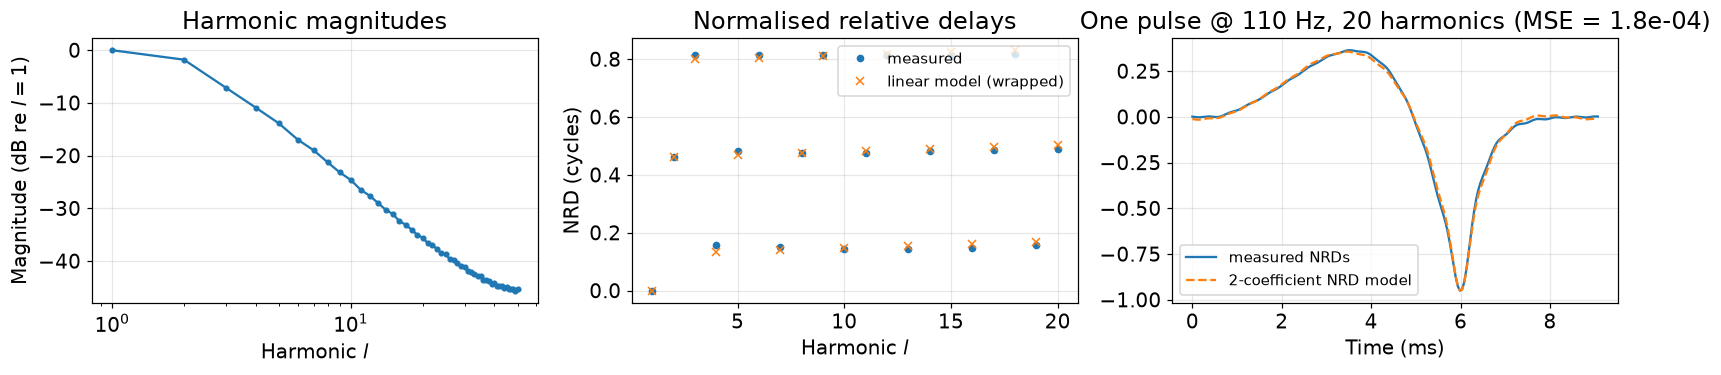

Phase storage: 20 floats  ->  NRD model: 2 floats


In [33]:
LF_MAG_DB = loadmat('LFmag.mat')['LFmag'][0]   # measured LF harmonic magnitudes (dB)
LF_NRD = loadmat('LFNRD.mat')['LFNRD'][0]      # measured LF normalised relative delays (first 20 harmonics)

N_HARM = 50                                     # harmonics used by the converter
LF_MAG = 10**(LF_MAG_DB[:N_HARM] / 20)
NRD_FIT = [0.335465, -0.207431]                 # first-order NRD model (slope, offset)
NRD_APPROX = np.mod(np.insert(np.polyval(NRD_FIT, np.arange(2, N_HARM)), 0, 0.0), 1)


def single_lf_pulse(f0, mag=LF_MAG, nrd=NRD_APPROX, gain=0.95, fs=FS):
    """One period of the GFD as a sum of harmonics (Python twin of the STM32 genPulse())."""
    t = np.arange(0, 1 / f0, 1 / fs)
    l = np.arange(1, len(nrd) + 1)[:, None]
    g = np.sum(mag[:len(nrd), None] * np.sin(2 * np.pi * l * f0 * t + 2 * np.pi * nrd[:, None]), axis=0)
    return gain * g / np.max(np.abs(g))


# compare measured vs. modelled NRDs over the harmonics we have measurements for
L = len(LF_NRD)
nrd_measured = np.mod(LF_NRD, 1)
p_meas = single_lf_pulse(f0_demo, nrd=nrd_measured)
p_appr = single_lf_pulse(f0_demo, nrd=NRD_APPROX[:L])
mse = np.mean((p_meas - p_appr)**2)

fig, axs = plt.subplots(1, 3, figsize=(15, 3.6))
harm = np.arange(1, N_HARM + 1)
axs[0].semilogx(harm, LF_MAG_DB[:N_HARM] - LF_MAG_DB[0], 'o-', ms=3)
axs[0].set(xlabel='Harmonic $l$', ylabel='Magnitude (dB re $l=1$)', title='Harmonic magnitudes')
axs[1].plot(harm[:L], nrd_measured, 'o', ms=4, label='measured')
axs[1].plot(harm[:L], NRD_APPROX[:L], 'x', ms=5, label='linear model (wrapped)')
axs[1].set(xlabel='Harmonic $l$', ylabel='NRD (cycles)', title='Normalised relative delays')
axs[1].legend(fontsize=10)
tp = np.arange(len(p_meas)) / FS * 1e3
axs[2].plot(tp, p_meas, label='measured NRDs')
axs[2].plot(tp, p_appr, '--', label='2-coefficient NRD model')
axs[2].set(xlabel='Time (ms)', title=f'One pulse @ {f0_demo} Hz, {L} harmonics (MSE = {mse:.1e})')
axs[2].legend(fontsize=10)
plt.tight_layout()
plt.show()

print(f'Phase storage: {L} floats  ->  NRD model: {len(NRD_FIT)} floats')

### 1.3 Fundamental-frequency contour

A whisper carries no pitch, so prosody has to be *invented*. Following Ferreira (2016), every voiced stretch starts a stylised $F_0$ gesture: a short damped oscillation around the speaker's average $\hat F_0$ with a slow declination.

$$
F_0(t) = \phi\left[\hat F_0 (1-\alpha t)\, e^{-\beta t} \sin(\gamma t - 0.3\pi) - \theta t + \hat F_0\right]
$$

($\alpha = 0.13,\ \beta = 0.6,\ \gamma \approx \pi,\ \theta = 5$. The curve is shifted so that $F_0(0.5\,\text{s}) = \hat F_0$, as in `SegmentationF0`.) In the full system the contour **restarts at every voiced onset** and resets during unvoiced or silent frames.

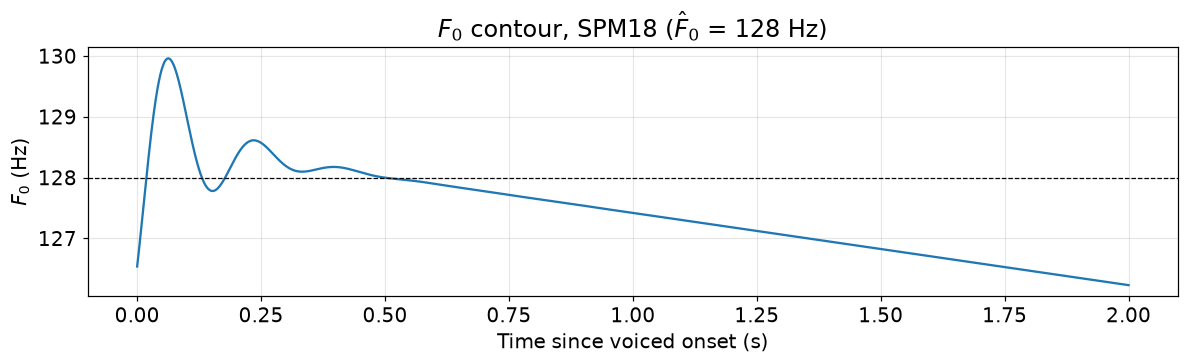

In [34]:
# Settings for test speaker SPM18 (Table 7.2)
F0_AVG = 128        # average F0 of the voiced reference (Hz)
F_VUV = 1800        # CoG below this -> vocalic (Hz)
F_UV = 2400         # CoG above this -> unvoiced (Hz)


def f0_contour(t, F0, alpha=0.13, beta=0.6, gamma=12 * 2 * np.pi / 25, theta=5, phi=0.02):
    """Stylised F0 gesture (Hz) for time t (s) after a voiced onset."""
    x_scale = N2**2 / FS    # the original code's frame-rate scaling of the time axis

    def shape(x):
        return F0 * (1 - alpha * x) * np.exp(-beta * x) * np.sin(gamma * x - 0.3 * np.pi) - theta * x + F0

    return (shape(t * x_scale) - shape(0.5 * x_scale)) * phi + F0


t_c = np.arange(int(2 * FS)) / FS
fig, ax = plt.subplots()
ax.plot(t_c, f0_contour(t_c, F0_AVG))
ax.axhline(F0_AVG, ls='--', color='k', lw=0.8)
ax.set(xlabel='Time since voiced onset (s)', ylabel='$F_0$ (Hz)',
       title=f'$F_0$ contour, SPM18 ($\\hat F_0$ = {F0_AVG} Hz)')
plt.tight_layout()
plt.show()

### 1.4 Pulse trains: discrete vs. continuous $F_0$

> _**TODO**: remove this section maybe_

There are two ways to follow the contour:

- **Discrete** (STM32 and the converter): each pulse uses the $F_0$ at its first sample and keeps it for the whole period.
- **Continuous**: $F_0$ changes sample by sample, so the phase is the running integral $\int F_0\,dt$.

The discrete version is cheaper but smears the upper harmonics (Fig. 4.6). Listen for the difference at $\hat F_0 = 250$ Hz.

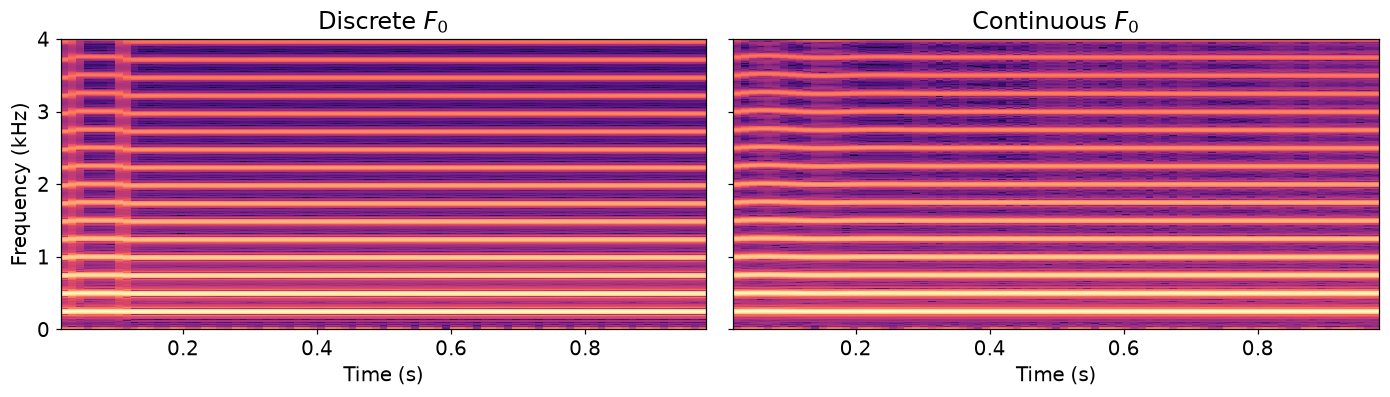

Discrete F_0


Continuous F_0


In [ ]:
def pulse_train_discrete(contour, fs=FS):
    """Concatenate LF periods, each frozen at the F0 of its first sample."""
    out, pos = [], 0
    while pos < len(contour):
        f0 = contour[pos]
        tp = np.arange(0, 1 / f0, 1 / fs)
        out.append(v_glotlf(1, tp * f0))
        pos += len(tp)
    return np.concatenate(out)[:len(contour)]


def pulse_train_continuous(contour, fs=FS):
    """LF waveform driven by the integrated instantaneous F0 (phase in periods)."""
    return v_glotlf(1, np.cumsum(contour) / fs)


contour_250 = f0_contour(np.arange(FS) / FS, 250, phi=0.01)
trains = {'Discrete $F_0$': pulse_train_discrete(contour_250),
          'Continuous $F_0$': pulse_train_continuous(contour_250)}

fig, axs = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
for ax, (name, x) in zip(axs, trains.items()):
    specshow(ax, x, fmax=4000, nfft=4 * N, nperseg=N)
    ax.set_title(name)
axs[1].set_ylabel('')
plt.tight_layout()
plt.show()

for name, x in trains.items():
    play(x, label=name.replace('$', ''))

## 2 · Vocal-tract filter (Ch. 5)

The vocal tract is modelled as an all-pole filter $H(z) = b_0 / A(z)$ of order $p = 22$. Its coefficients are estimated **in the frequency domain**:

![LPC analysis chain](figures/lpcAnalysis.png)

We work from the PSD because every later step (tilt compensation, interpolating between frames, the centre of gravity) is a simple operation on it.

### 2.1 Odd-frequency DFT (ODFT)

The ODFT puts its bins at half-integer frequencies, $f_k = (k + \tfrac12)\,F_s/N$:

$$X_O[k] = \sum_{n=0}^{N-1} x[n]\,h[n]\,e^{-j\frac{2\pi}{N}(k+\frac12)n}, \qquad h[n] = \sin\!\left(\frac{\pi(n+\frac12)}{N}\right)$$

The **sine window** meets the Princen–Bradley condition $h^2[n] + h^2[n+N/2] = 1$. That makes 50 %-overlapped analysis and synthesis exact, which is why this window appears on both sides of the overlap-add.

> The reason for using the ODFT is that the regular DFT with frequency bins at integer multiples of 1/T (where T is the signal duration), given an inaccurate representation of the freq. spectrum near the top and bottom ends of the band.

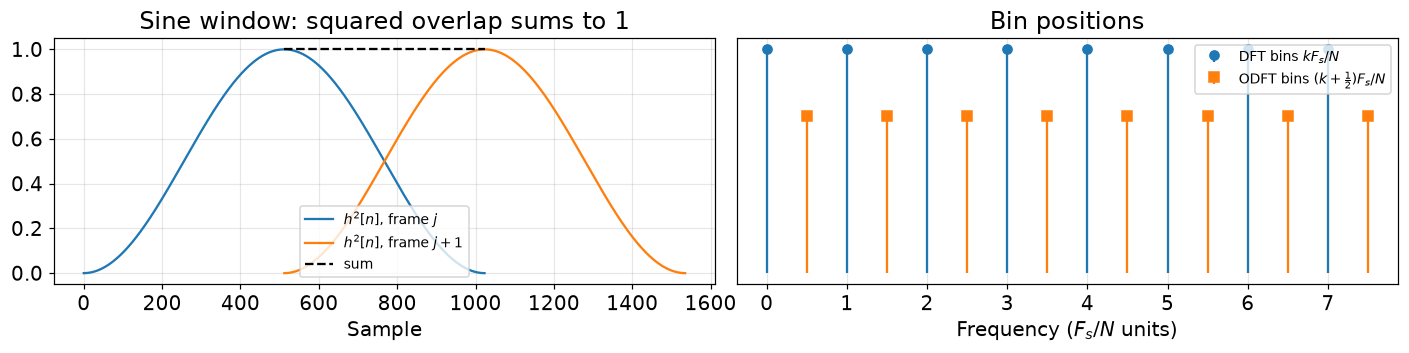

In [40]:
SINE_WIN = np.sin(np.pi * (np.arange(N) + 0.5) / N)


def odft(x, n=N):
    """Odd-frequency DFT: modulate by e^{-jπn/N}, then a standard FFT."""
    return np.fft.fft(x * np.exp(-1j * np.pi * np.arange(n) / n))


def iodft(X, n=N):
    """Inverse ODFT."""
    return np.fft.ifft(X) * np.exp(1j * np.pi * np.arange(n) / n)


x_test = np.random.default_rng(0).standard_normal(N)
assert np.allclose(iodft(odft(x_test)), x_test)                # perfect reconstruction
assert np.allclose(SINE_WIN[:N2]**2 + SINE_WIN[N2:]**2, 1.0)   # Princen–Bradley condition

# A real signal's ODFT is conjugate-symmetric about the middle: X[k] = X*[N-1-k].
# Every one-sided PSD in this notebook is mirrored with np.concatenate([P, P[::-1]]).
X_test = odft(x_test)
assert np.allclose(X_test, np.conj(X_test[::-1]))

fig, axs = plt.subplots(1, 2, figsize=(13, 3.4))
n = np.arange(N + N2)
axs[0].plot(n[:N], SINE_WIN**2, label='$h^2[n]$, frame $j$')
axs[0].plot(n[N2:], SINE_WIN**2, label='$h^2[n]$, frame $j+1$')
axs[0].plot(n[N2:N], SINE_WIN[N2:]**2 + SINE_WIN[:N2]**2, 'k--', label='sum')
axs[0].set(xlabel='Sample', title='Sine window: squared overlap sums to 1')
axs[0].legend(fontsize=9, loc='lower center')

k = np.arange(8)
axs[1].stem(k, np.ones_like(k), linefmt='C0-', markerfmt='C0o', basefmt=' ', label='DFT bins $k F_s/N$')
axs[1].stem(k + 0.5, 0.7 * np.ones_like(k), linefmt='C1-', markerfmt='C1s', basefmt=' ', label='ODFT bins $(k+\\frac{1}{2}) F_s/N$')
axs[1].set(xlabel='Frequency ($F_s/N$ units)', yticks=[], title='Bin positions')
axs[1].legend(fontsize=9, loc='upper right')
plt.tight_layout()
plt.show()

### 2.2 From PSD to filter: Wiener–Khinchin + Levinson–Durbin

**Wiener–Khinchin**: the autocorrelation is the inverse transform of the PSD, $r[\tau] = \mathcal{F}^{-1}\{|X_O[k]|^2\}$.

**Levinson–Durbin** then solves the Toeplitz (Yule–Walker) normal equations for $a_1 \dots a_p$ in $O(p^2)$ rather than $O(p^3)$. The final prediction error $E$ sets the gain, $b_0 = \sqrt{E}$ (autocorrelation matching).

We check the chain in two ways: against MATLAB's `levinson`, and by recovering a known resonator from noise it filtered.

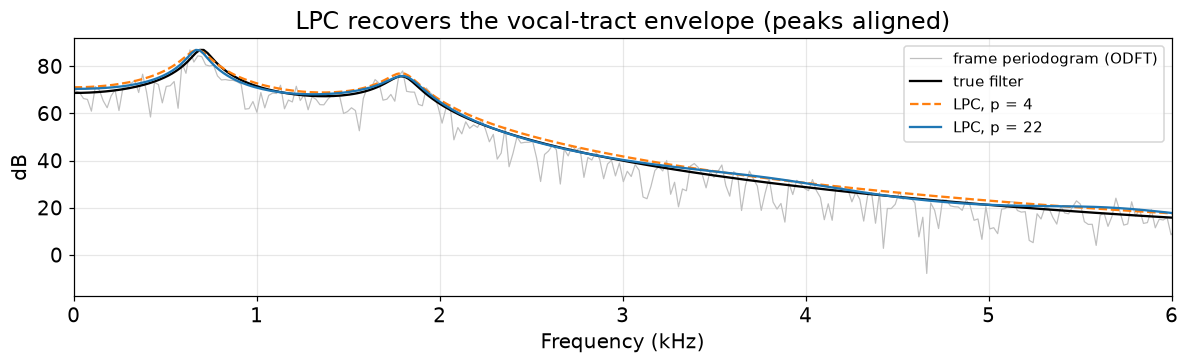

In [45]:
def levinson(r, p):
    """Levinson-Durbin recursion: autocorrelation r -> A(z) coefficients a, prediction error E, reflection coeffs k."""
    a = np.zeros(p + 1)
    a[0] = 1.0
    k = np.zeros(p)
    E = np.real(r[0])
    for i in range(1, p + 1):
        lam = -np.dot(r[1:i + 1], a[i - 1::-1]) / E
        a[1:i + 1] += lam * a[i - 1::-1]
        E *= 1.0 - lam**2
        k[i - 1] = -lam
    return a, E, k


def lpc_from_psd(psd, p=NLPC):
    """Full (mirrored) ODFT power spectrum -> all-pole filter (b0, a)."""
    r = iodft(psd).real                  # Wiener–Khinchin
    a, E, _ = levinson(r[:p + 1], p)
    return np.sqrt(E), a


def lpc_envelope_db(b0, a, n=N2):
    """Magnitude response of b0/A(z) in dB on n points up to Nyquist."""
    f, h = signal.freqz(b0, a, worN=n, fs=FS)
    return f, 20 * np.log10(np.abs(h) + 1e-12)


# 1) Against MATLAB: levinson([1 .7 0 .5 1 .5 0 .5 1], 6)
a_ml = np.array([1.0, -0.158730158730140, -0.603174603174617, -0.158730158730125,
                 -0.587301587301598, -0.317460317460331, 0.984126984126981])
assert np.allclose(levinson(np.array([1.0, 0.7, 0, 0.5, 1.0, 0.5, 0.0, 0.5, 1.0]), 6)[0], a_ml)

# 2) Recover a known two-resonance filter from one windowed frame of the noise it shaped
rng = np.random.default_rng(1)
a_true = np.array([1.0])
for F, B in ((700, 100), (1800, 150)):
    r_pole = np.exp(-np.pi * B / FS)
    a_true = np.convolve(a_true, [1, -2 * r_pole * np.cos(2 * np.pi * F / FS), r_pole**2])
frame = signal.lfilter([1], a_true, rng.standard_normal(4 * N))[-N:]
psd_frame = np.abs(odft(frame * SINE_WIN))**2

fig, ax = plt.subplots()
f_bins = (np.arange(N2) + 0.5) * FS / N
ax.plot(f_bins / 1e3, 10 * np.log10(psd_frame[:N2]), color='0.75', lw=0.8, label='frame periodogram (ODFT)')
for (b0, a), name, style in (((1.0, a_true), 'true filter', 'k-'),
                             (lpc_from_psd(psd_frame, 4), 'LPC, p = 4', 'C1--'),
                             (lpc_from_psd(psd_frame, NLPC), f'LPC, p = {NLPC}', 'C0-')):
    f, env = lpc_envelope_db(b0, a)
    ax.plot(f / 1e3, env - env.max() + 10 * np.log10(psd_frame.max()), style, label=name)
ax.set(xlabel='Frequency (kHz)', ylabel='dB', xlim=(0, 6), title='LPC recovers the vocal-tract envelope (peaks aligned)')
ax.legend(fontsize=10)
plt.tight_layout()
plt.show()

### 2.3 Filter realisation: Direct Form II

On the STM32 the filter runs as a Direct Form II structure. Because the numerator is only $b_0$, it needs **a single delay line** $w$:

$$
w[n] = x[n] - \sum_{k=1}^{p} a_k\, w[n-k], \qquad y[n] = b_0\, w[n]
$$

The function below translates `iirDirectTypeII()` from the C code line for line and is checked against `scipy.signal.lfilter`. The rest of the notebook uses `lfilter` for speed.

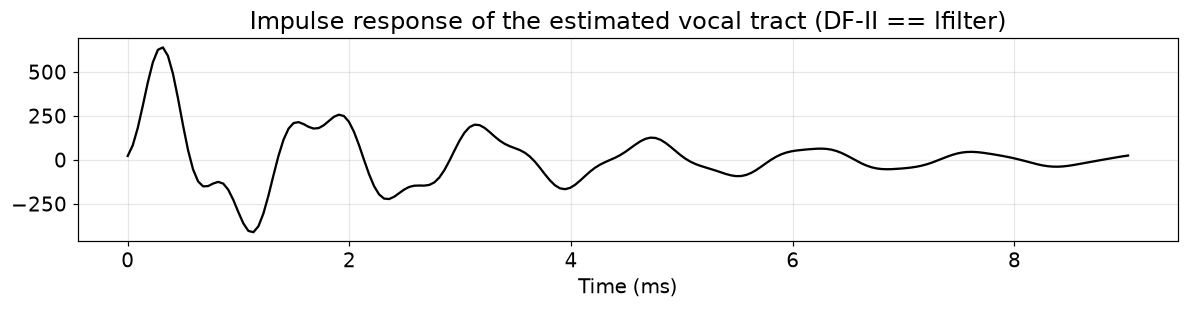

In [42]:
def iir_df2(x, b0, a):
    """All-pole Direct Form II filter, as in the STM32 iirDirectTypeII()."""
    w = np.zeros(len(a))                 # delay line w[n], w[n-1], ..., w[n-p]
    y = np.zeros(len(x))
    for n, xn in enumerate(x):
        w[0] = xn - np.dot(a[1:], w[1:])
        y[n] = b0 * w[0]
        w[1:] = w[:-1].copy()            # shift the delay line
    return y


b0_t, a_t = lpc_from_psd(psd_frame)
x_imp = np.r_[1.0, np.zeros(N2 - 1)]
assert np.allclose(iir_df2(x_imp, b0_t, a_t), signal.lfilter([b0_t], a_t, x_imp))

fig, ax = plt.subplots(figsize=(11, 3))
ax.plot(np.arange(200) / FS * 1e3, iir_df2(x_imp, b0_t, a_t)[:200], color='k')
ax.set(xlabel='Time (ms)', title='Impulse response of the estimated vocal tract (DF-II == lfilter)')
plt.tight_layout()
plt.show()

### 2.4 Spectral tilt compensation

The envelope we estimate from the whisper describes what the **output** should look like. The LF pulses already roll off towards high frequencies, though. Filtering them through that envelope as-is would apply the roll-off twice and muffle the result. So before computing the filter, we **divide the PSD by the pulse's spectral tilt**.

Following Ferreira, the tilt is approximated by three straight segments over log-frequency, relative to $f/F_0$:

$$
G(f) =
\begin{cases}
0\ \text{dB} & f/F_0 < 1 \\
m_1 \log_{10}(f/F_0) + b_1 & 1 \le f/F_0 < 2 \\
m_2 \log_{10}(f/F_0) + b_2 & f/F_0 \ge 2
\end{cases}
$$

Because $G$ depends on $F_0$, it is precomputed once for the speaker's average $\hat F_0$.

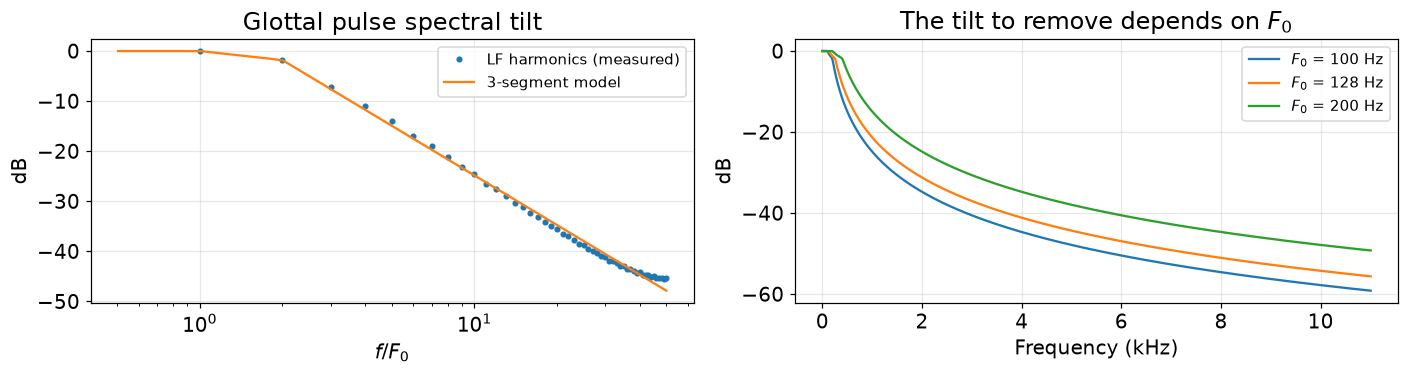

m1 = -5.97 dB/decade, m2 = -32.95 dB/decade


In [43]:
# Fit the two sloped segments to the measured LF harmonic magnitudes (dB re. the fundamental)
lf_rel_db = LF_MAG_DB - LF_MAG_DB[0]
log_h = np.log10(np.arange(1, len(lf_rel_db) + 1))
m1, b1 = np.polyfit(log_h[:2], lf_rel_db[:2], 1)        # harmonics 1–2
m2, b2 = np.polyfit(log_h[1:48], lf_rel_db[1:48], 1)    # harmonics 2–48
b2 += (m1 * log_h[1] + b1) - (m2 * log_h[1] + b2)       # join the segments at the 2nd harmonic


def tilt_gain(f0, n=N, fs=FS):
    """Linear LF tilt magnitude on the n-point grid, mirrored like an ODFT spectrum."""
    ratio = np.arange(n // 2) * fs / (f0 * n)
    with np.errstate(divide='ignore'):
        g_db = np.where(ratio < 1, 0.0,
                        np.where(ratio < 2, m1 * np.log10(ratio) + b1, m2 * np.log10(ratio) + b2))
    g = 10**(g_db / 20)
    return np.concatenate([g, g[::-1]])


fig, axs = plt.subplots(1, 2, figsize=(13, 3.6))
ratio = np.arange(N2) * FS / (F0_AVG * N)
keep = (ratio >= 0.5) & (ratio <= len(lf_rel_db))
axs[0].semilogx(np.arange(1, len(lf_rel_db) + 1), lf_rel_db, 'o', ms=3, label='LF harmonics (measured)')
axs[0].semilogx(ratio[keep], 20 * np.log10(tilt_gain(F0_AVG)[:N2][keep]), 'C1', label='3-segment model')
axs[0].set(xlabel='$f / F_0$', ylabel='dB', title='Glottal pulse spectral tilt')
axs[0].legend(fontsize=10)

f_axis = np.arange(N2) * FS / N
for f0 in (100, F0_AVG, 200):
    axs[1].plot(f_axis / 1e3, 20 * np.log10(tilt_gain(f0)[:N2]), label=f'$F_0$ = {f0} Hz')
axs[1].set(xlabel='Frequency (kHz)', ylabel='dB', title='The tilt to remove depends on $F_0$')
axs[1].legend(fontsize=10)
plt.tight_layout()
plt.show()

print(f'm1 = {m1:.2f} dB/decade, m2 = {m2:.2f} dB/decade')

### 2.5 Putting the source and the filter together: vowel synthesis

Before tackling whispers, we validate source + filter on their own. Each EP tonic vowel is given as a spectral envelope (in dB) measured from a high-pitched female voice. We:

1. subtract the LF tilt at $F_0 = 250$ Hz,
2. turn the envelope into a filter with IODFT and Levinson ($p = 22$),
3. excite it with an LF pulse train that follows the $F_0$ contour.

> Expects the templates at `data/templates/sofia_{a,e,i,o,u}_hlpc.mat` (variable `sumhLPC`).

In [46]:
from pathlib import Path

DATA_DIR = Path('data')
VOWELS = 'aeiou'
F0_VOWEL = 250      # the templates come from a high-pitched female voice

templates = {v: loadmat(DATA_DIR / 'templates' / f'sofia_{v}_hlpc.mat')['sumhLPC'][0] for v in VOWELS}


def envelope_to_lpc(env_db, f0, p=NLPC):
    """One-sided dB envelope (N2 points) -> tilt-compensated all-pole filter (b0, a)."""
    comp_db = env_db - 20 * np.log10(tilt_gain(f0)[:N2])
    psd = 10**(comp_db / 10)
    return lpc_from_psd(np.concatenate([psd, psd[::-1]]), p)


f_axis = np.linspace(0, FS / 2, N2)
fig, axs = plt.subplots(1, 2, figsize=(13, 3.8))
for v, env in templates.items():
    axs[0].plot(f_axis / 1e3, env, label=f'/{v}/')
axs[0].set(xlabel='Frequency (kHz)', ylabel='dB', title='Vowel spectral envelopes')
axs[0].legend(fontsize=10, ncol=5)

env_a = templates['a']
f, h_db = lpc_envelope_db(*envelope_to_lpc(env_a, F0_VOWEL))
axs[1].plot(f_axis / 1e3, env_a, label='template /a/')
axs[1].plot(f_axis / 1e3, env_a - 20 * np.log10(tilt_gain(F0_VOWEL)[:N2]), label='tilt compensated')
axs[1].plot(f / 1e3, h_db, '--', label=f'LPC fit (p = {NLPC})')
axs[1].set(xlabel='Frequency (kHz)', title='Template -> filter')
axs[1].legend(fontsize=10)
plt.tight_layout()
plt.show()

OSError: Reader needs file name or open file-like object

In [ ]:
def synth_vowel(env_db, f0=F0_VOWEL, dur=0.6, fade=0.02):
    """LF pulse train following the F0 contour, filtered by the vowel's LPC model."""
    pulses = pulse_train_discrete(f0_contour(np.arange(int(dur * FS)) / FS, f0, phi=0.01))
    b0, a = envelope_to_lpc(env_db, f0)
    y = signal.lfilter([b0], a, pulses)
    ramp = np.linspace(0, 1, int(fade * FS))
    y[:len(ramp)] *= ramp
    y[-len(ramp):] *= ramp[::-1]
    return y / np.max(np.abs(y))


gap = np.zeros(int(0.15 * FS))
vowel_seq = np.concatenate([np.r_[synth_vowel(env), gap] for env in templates.values()])

fig, ax = plt.subplots(figsize=(11, 3.5))
specshow(ax, vowel_seq, fmax=6000)
for i, v in enumerate(VOWELS):
    ax.text((i * (0.6 + 0.15) + 0.3), 5.5, f'/{v}/', color='w', ha='center', fontsize=14)
ax.set_title('Synthesised EP vowels (LF source + tilt-compensated LPC filter)')
plt.tight_layout()
plt.show()

play(vowel_seq, label='/a/ /e/ /i/ /o/ /u/')

## 3 · Overlap-add engine (Ch. 6.1)

Now the filter comes from the **whisper itself**. The engine runs like the STM32 DMA loop:

- Every 512 new input samples, the window `[previous | current]` (1024 samples, sine-windowed) gives a new PSD $P_j$.
- A 1024-sample **pulse buffer** shifts by 512. New pulses are generated wherever the previous pulse ended (`lastPulsePos`) until that position passes 512.
- Each pulse is filtered and **added** into the buffer, ring-out included, so neighbouring pulses overlap. The first 512 samples are then output.

Two ways to filter the pulses of one block:

| | filter | sounds like |
|---|---|---|
| **Frame filtering** | one $H_j(z)$ from $P_j$ for every pulse in the block | an electrolarynx: the envelope jumps every 23 ms |
| **Pulse filtering** | pulse $k$ gets $H_k(z)$ from $(1-\alpha_k)P_{j-1} + \alpha_k P_j$, with $\alpha_k = \text{pos}_k / 512$ | envelope glides smoothly from pulse to pulse |

![Per-pulse filtering](figures/pulseMap.png)

In [ ]:
WHISPER_FILE = DATA_DIR / 'whispered' / 'SPM18_AviaoWhisperd.wav'   # "A asa do avião andava avariada"


def load_wav(path, fs=FS):
    """Mono, resampled to fs, kept at int16 scale (the WAD thresholds assume it)."""
    fs_in, x = wavfile.read(path)
    x = x[:, 0] if x.ndim > 1 else x
    return signal.resample_poly(x.astype(float), fs, fs_in)


whisper = load_wav(WHISPER_FILE)
t_in = np.arange(len(whisper)) / FS

fig, axs = plt.subplots(2, 1, figsize=(11, 5), sharex=True)
axs[0].plot(t_in, whisper / INT16_MAX, lw=0.5, color='k')
axs[0].set(ylabel='Amplitude (FS)', title='Whispered input, SPM18', xlim=(0, t_in[-1]))
specshow(axs[1], whisper)
plt.tight_layout()
plt.show()

play(whisper, label='Whispered input')

In [ ]:
F0_MIN = 50          # lowest F0 the pulse buffer is sized for (Hz)
PULSE_TAIL = 300     # samples of filter ring-out kept after each pulse
PSD_FLOOR = 1e-6     # keeps Levinson finite on digitally silent frames


def analysis_frames(x):
    """Yield (frame index, 512 new samples, ODFT power spectrum of the sine-windowed [prev | new])."""
    old = np.zeros(N2)
    for j, start in enumerate(range(0, len(x) - N2, N2)):
        new = x[start:start + N2]
        yield j, new, np.abs(odft(np.concatenate([old, new]) * SINE_WIN))**2 + PSD_FLOOR
        old = new


def convert(x, f0=F0_AVG, mode='pulse', segmentation=False, contour=False,
            f_vuv=F_VUV, f_uv=F_UV, noise_gain=0.2, legacy_output_window=False, seed=0):
    """Whisper -> voiced speech, block by block as on the STM32.

    mode          'frame': one LPC filter per block; 'pulse': one filter per pulse from the interpolated PSD
    segmentation  WAD activity + centre-of-gravity voicing (wad / cog_mapping are defined in §4)
    contour       F0 follows f0_contour, restarting at each voiced onset; otherwise constant f0
    legacy_output_window  re-apply the sine window to consecutive output blocks, as overlapAdd.ipynb did
    """
    noise = np.random.default_rng(seed).normal(0, 0.1, N)   # fixed noise template, reused by every pulse
    tilt = tilt_gain(f0)
    buf = np.zeros(max(N, N2 + int(np.ceil(FS / F0_MIN)) + PULSE_TAIL))
    old_psd, old_out = np.zeros(N), np.zeros(N2)
    pos, onset = 1, 0        # pos starts at 1 so alpha > 0 against the all-zero first PSD
    out = []
    trace = dict(cog=[], beta=[], activity=[], pulses=[])

    for j, new, psd in analysis_frames(x):
        beta, activity = 0.0, 1.0
        if segmentation:
            cog = centre_of_gravity(psd)
            beta, activity = cog_mapping(cog, f_vuv, f_uv), wad(new)
            trace['cog'].append(cog)
        trace['beta'].append(beta)
        trace['activity'].append(activity)

        # NB: as in the thesis code, the PSD (power) is divided by the tilt *magnitude*
        if mode == 'frame':
            b0, a = lpc_from_psd(psd / tilt)

        buf[:-N2] = buf[N2:]     # advance the pulse buffer by one block
        buf[-N2:] = 0
        while pos < N2:
            if contour:
                f_start = f0_contour(onset / FS, f0)
                tp = np.arange(0, 1 / f_start, 1 / FS)
                pulse = v_glotlf(1, tp * f0_contour((onset + np.arange(len(tp))) / FS, f0))
                onset += int(FS / f_start)
            else:
                pulse = single_lf_pulse(f0)

            if segmentation:
                mix = 0.5 * beta + 0.5            # keeps some noise even in fully voiced frames
                pulse = (pulse * (1 - mix) + noise_gain * noise[:len(pulse)] * mix) * activity

            alpha = pos / N2
            if mode == 'pulse':
                b0, a = lpc_from_psd((alpha * psd + (1 - alpha) * old_psd) / tilt)

            y = signal.lfilter([b0], a, np.r_[pulse, np.zeros(PULSE_TAIL)])
            buf[pos:pos + len(y)] += y
            trace['pulses'].append((j, pos, alpha))
            pos += len(pulse)

        pos -= N2
        if contour and (beta > 0.5 or activity < 0.5):
            onset = 0                             # restart the F0 gesture at the next voiced onset
        old_psd = psd

        block = buf[:N2].copy()
        out.append(old_out * SINE_WIN[:N2] + block * SINE_WIN[N2:] if legacy_output_window else block)
        old_out = block

    return np.concatenate(out), {k: np.array(v) for k, v in trace.items()}

### 3.1 Inside one block

We run both variants over the whole recording, then zoom in on a single block $j$ (by default the loudest one). The left panel shows the envelope each pulse is filtered with: it slides from $P_{j-1}$ towards $P_j$ as $\alpha_k$ grows. The right panel shows the resulting 512 output samples.

In [ ]:
y_frame, tr_frame = convert(whisper, mode='frame')
y_pulse, tr_pulse = convert(whisper, mode='pulse')

psds = [P for _, _, P in analysis_frames(whisper)]
J = int(np.argmax([P[:N2].sum() for P in psds]))     # loudest block; set by hand to inspect others
pulses_J = tr_pulse['pulses'][tr_pulse['pulses'][:, 0] == J]
tilt = tilt_gain(F0_AVG)

fig, axs = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw={'width_ratios': [3, 2]})
for P, ls, name in ((psds[J - 1], ':', '$P_{j-1}$'), (psds[J], '--', '$P_j$')):
    f, env = lpc_envelope_db(*lpc_from_psd(P / tilt))
    axs[0].plot(f / 1e3, env, color='k', ls=ls, lw=1.3, label=name)
for _, pos, alpha in pulses_J:
    f, env = lpc_envelope_db(*lpc_from_psd((alpha * psds[J] + (1 - alpha) * psds[J - 1]) / tilt))
    axs[0].plot(f / 1e3, env, color=plt.cm.coolwarm(alpha), label=f'pulse at {int(pos)}, $\\alpha$ = {alpha:.2f}')
axs[0].set(xlabel='Frequency (kHz)', ylabel='dB', xlim=(0, 6), title=f'Filter envelope per pulse, block j = {J}')
axs[0].legend(fontsize=9)

n_blk = np.arange(J * N2, (J + 1) * N2)
axs[1].plot(n_blk - J * N2, y_frame[n_blk] / np.max(np.abs(y_frame)), color='tab:orange', lw=1, label='frame filtering')
axs[1].plot(n_blk - J * N2, y_pulse[n_blk] / np.max(np.abs(y_pulse)), color='tab:blue', lw=1, label='pulse filtering')
for _, pos, alpha in pulses_J:
    axs[1].axvline(pos, color=plt.cm.coolwarm(alpha), ls='--', lw=0.8)
axs[1].set(xlabel='Sample within block', title='Output block (pulse starts dashed)')
axs[1].legend(fontsize=9, loc='lower right')
plt.tight_layout()
plt.show()

### 3.2 Frame filtering vs. pulse filtering

Both are still "fully voiced": every frame is excited by pulses at a constant $\hat F_0$, even fricatives and pauses. That is the problem §4 solves. Listen for the 23 ms "steps" in frame filtering.

In [ ]:
t0 = max(0.0, J * N2 / FS - 0.1)           # 250 ms around the inspected block
zoom = slice(int(t0 * FS), int((t0 + 0.25) * FS))
t_zoom = np.arange(zoom.start, zoom.stop) / FS

fig, axs = plt.subplots(2, 2, figsize=(14, 6), sharex='col')
for row, (name, y, color) in enumerate((('Frame filtering', y_frame, 'tab:orange'),
                                        ('Pulse filtering', y_pulse, 'tab:blue'))):
    axs[row, 0].plot(t_zoom, y[zoom] / np.max(np.abs(y[zoom])), color=color, lw=0.8)
    axs[row, 0].set(ylabel=name, xlim=(t_zoom[0], t_zoom[-1]))
    specshow(axs[row, 1], y)
    axs[row, 1].set_title(name)
axs[1, 0].set_xlabel('Time (s)')
plt.tight_layout()
plt.show()

play(whisper, label='Whispered')
play(y_frame, label='Frame filtering')
play(y_pulse, label='Pulse filtering')

## 4 · Segmentation (Ch. 6.2–6.3)

Voicing every frame is wrong in two ways: **pauses** become buzz, and **unvoiced consonants** (/s/, /ʃ/, /f/…) become vowels. Two cheap per-frame features fix that.

### 4.1 Whisper activity detection (WAD)

A modified G.729 VAD looks at each block's energy $E$ and zero-crossing rate $\gamma$:

$$
\text{activity} =
\begin{cases}
1 & E \ge \zeta_2 \\
0 & E < \zeta_1 \\
\tfrac12\left(\operatorname{sign}(\gamma - \zeta_{zcr}) + 1\right) & \text{otherwise}
\end{cases}
$$

The thresholds were tuned by hand for each speaker. Silent blocks mute the excitation, and they also reset the $F_0$ contour.

In [ ]:
WAD_Z1 = 0.0005e9   # below: silence  (block energy, int16 scale, 512 samples)
WAD_Z2 = 0.002e9    # above: speech
WAD_ZCR = 0.0       # zero-crossing threshold for the grey zone


def zero_crossing_rate(frame):
    return np.sum(frame[:-1] * frame[1:] < 0) / len(frame)


def wad(frame, z1=WAD_Z1, z2=WAD_Z2, z_zcr=WAD_ZCR):
    """Modified G.729 whisper activity detection on the 512 new samples of a block."""
    energy = np.sum(frame**2)
    if energy >= z2:
        return 1.0
    if energy < z1:
        return 0.0
    return 0.5 * np.sign(zero_crossing_rate(frame) - z_zcr) + 0.5


blocks = [new for _, new, _ in analysis_frames(whisper)]
t_blk = (np.arange(len(blocks)) + 0.5) * N2 / FS
energy = np.array([np.sum(b**2) for b in blocks])
zcr = np.array([zero_crossing_rate(b) for b in blocks])
activity = np.array([wad(b) for b in blocks])

fig, axs = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
specshow(axs[0], whisper)
ax_r = axs[0].twinx()
ax_r.step(t_blk, activity, where='mid', color='w', lw=1.5)
ax_r.set(ylim=(-0.05, 1.6), ylabel='activity')
axs[0].set_title('WAD decision over the whisper')

axs[1].semilogy(t_blk, energy, color='k', label='block energy $E$')
for z, name in ((WAD_Z1, r'$\zeta_1$'), (WAD_Z2, r'$\zeta_2$')):
    axs[1].axhline(z, ls='--', color='tab:red', lw=0.9)
    axs[1].text(t_blk[-1], z, ' ' + name, va='center', color='tab:red')
ax_z = axs[1].twinx()
ax_z.plot(t_blk, zcr, color='tab:blue', lw=0.8)
ax_z.set_ylabel('ZCR', color='tab:blue')
axs[1].set(xlabel='Time (s)', ylabel='Energy', xlim=(0, t_blk[-1]))
axs[1].legend(fontsize=9, loc='upper left')
plt.tight_layout()
plt.show()

### 4.2 Voicing from the spectral centre of gravity

In whispered **vowels** the energy sits around the formants (low). In **fricatives** it sits high. The spectral centre of gravity (Perrotin et al.) captures this in a single number per block:

$$
\text{CoG} = \frac{\sum_{k=0}^{N/2} f_k\, P[k]}{\sum_{k=0}^{N/2} P[k]}
$$

A sigmoid maps it to the **voicing coefficient** $\beta \in [0, 1]$ (0 = vocalic, 1 = unvoiced). The curve is centred on $\sqrt{F_{vuv}F_{uv}}$, and its steepness is set by $\tau$, the fraction of the $[F_{vuv}, F_{uv}]$ range that the transition fills:

$$
\beta = \sigma(\text{CoG}) = \frac{1}{1 + e^{-\lambda(\text{CoG} - \sqrt{F_{vuv}F_{uv}})}}, \qquad
\lambda = \frac{2}{F_{uv} - F_{vuv}} \ln\frac{1+\tau}{1-\tau}
$$

For SPM18, $F_{vuv} = 1.8$ kHz and $F_{uv} = 2.4$ kHz.

In [ ]:
def centre_of_gravity(psd, fs=FS):
    """Power-weighted mean frequency (Hz) of the one-sided spectrum."""
    n = len(psd)
    f = np.arange(n // 2) * fs / n
    return np.sum(f * psd[:n // 2]) / np.sum(psd[:n // 2])


def cog_mapping(cog, f_vuv=F_VUV, f_uv=F_UV, tau=0.99):
    """Sigmoid CoG -> voicing coefficient beta (0 = vocalic, 1 = unvoiced)."""
    lam = 2 / (f_uv - f_vuv) * np.log((1 + tau) / (1 - tau))
    return 1 / (1 + np.exp(-lam * (cog - np.sqrt(f_vuv * f_uv))))


cog = np.array([centre_of_gravity(P) for _, _, P in analysis_frames(whisper)])
beta = cog_mapping(cog)

fig = plt.figure(figsize=(14, 6))
gs = fig.add_gridspec(2, 3)
ax_sig = fig.add_subplot(gs[:, 0])
f_sweep = np.linspace(0, 5000, 1000)
for tau in (0.9, 0.99, 0.999):
    ax_sig.plot(f_sweep / 1e3, cog_mapping(f_sweep, tau=tau), label=f'$\\tau$ = {tau}')
for f_th, name in ((F_VUV, '$F_{vuv}$'), (F_UV, '$F_{uv}$')):
    ax_sig.axvline(f_th / 1e3, ls='--', color='k', lw=0.8)
    ax_sig.text(f_th / 1e3, 1.03, name, ha='center', transform=ax_sig.get_xaxis_transform())
ax_sig.set(xlabel='CoG (kHz)', ylabel=r'$\beta$', title='Mapping function', ylim=(-0.05, 1.05))
ax_sig.legend(fontsize=9, loc='center right')

ax_spec = fig.add_subplot(gs[0, 1:])
specshow(ax_spec, whisper, fmax=6000)
ax_spec.plot(t_blk, cog / 1e3, color='w', lw=1.2, label='CoG')
for f_th in (F_VUV, F_UV):
    ax_spec.axhline(f_th / 1e3, ls='--', color='c', lw=0.8)
ax_spec.set(title='Centre of gravity', xlabel='')
ax_spec.legend(fontsize=9, loc='upper right')

ax_b = fig.add_subplot(gs[1, 1:], sharex=ax_spec)
ax_b.fill_between(t_blk, beta, step='mid', color='tab:red', alpha=0.4, label=r'$\beta$ (unvoiced)')
ax_b.step(t_blk, activity, where='mid', color='k', lw=1, label='WAD activity')
ax_b.set(xlabel='Time (s)', ylim=(-0.05, 1.1), xlim=(0, t_blk[-1]))
ax_b.legend(fontsize=9, loc='upper right', ncol=2)
plt.tight_layout()
plt.show()

### 4.3 Mixing the excitation

Each pulse period is replaced by a blend of the LF pulse $g$ and noise $\nu$, then gated by the activity:

$$
e[n] = \big((1-m)\,g[n] + m\,\nu[n]\big)\cdot\text{activity}, \qquad m = 0.5\,\beta + 0.5
$$

The offset means even a fully vocalic block keeps some noise ($m \ge 0.5$), which sounds less synthetic than a pure pulse train. Because the noise is much weaker than the pulse, $m = 0.5$ still sounds clearly voiced.

In [ ]:
rng = np.random.default_rng(0)
g = v_glotlf(1, np.arange(int(3 * FS / F0_AVG)) * F0_AVG / FS)   # three LF periods
nu = 0.2 * rng.normal(0, 0.1, len(g))                             # same noise level as convert()

fig, axs = plt.subplots(1, 3, figsize=(14, 3.2))                  # own y-scale each: the noise is tiny
for ax, b in zip(axs, (0.0, 0.5, 1.0)):
    m = 0.5 * b + 0.5
    ax.plot(np.arange(len(g)) / FS * 1e3, (1 - m) * g + m * nu, color='k', lw=0.8)
    ax.set(title=f'$\\beta$ = {b}  ->  m = {m}', xlabel='Time (ms)')
axs[0].set_ylabel('Excitation')
plt.tight_layout()
plt.show()

## 5 · Complete system (Ch. 6.4, 7)

Everything together: per-pulse filtering, plus WAD, centre-of-gravity voicing, and the $F_0$ contour restarting at each voiced onset. These are the stimuli of the MUSHRA whisper-to-speech test:

| Condition | What it is |
|---|---|
| Whispered | the input |
| Frame filtering | one filter per block, constant $\hat F_0$ (electrolarynx-like) |
| Pulse filtering | per-pulse interpolated filters, constant $\hat F_0$ |
| Complete system | pulse filtering + WAD + V/UV mixing + $F_0$ contour |

In [ ]:
# legacy_output_window=True reproduces how the frame/pulse filtering stimuli were rendered (overlapAdd.ipynb);
# the complete-system stimuli (SegmentationF0.ipynb) were rendered without it.
CONDITIONS = {
    'Frame filtering': dict(mode='frame', legacy_output_window=True),
    'Pulse filtering': dict(mode='pulse', legacy_output_window=True),
    'Complete system': dict(mode='pulse', segmentation=True, contour=True),
}

outputs = {'Whispered': whisper}
traces = {}
for name, kw in CONDITIONS.items():
    outputs[name], traces[name] = convert(whisper, **kw)

fig, axs = plt.subplots(len(outputs), 1, figsize=(12, 2.4 * len(outputs)), sharex=True)
for ax, (name, y) in zip(axs, outputs.items()):
    specshow(ax, y, fmax=6000)
    ax.set(title=name, xlabel='')

tr = traces['Complete system']
ax_v = axs[-1].twinx()
ax_v.step(t_blk, tr['beta'], where='mid', color='w', lw=1.2, label=r'$\beta$')
ax_v.step(t_blk, tr['activity'], where='mid', color='c', lw=1.0, ls='--', label='activity')
ax_v.set(ylim=(-0.05, 1.8), yticks=[0, 1])
ax_v.legend(fontsize=9, loc='upper right', ncol=2)
axs[-1].set_xlabel('Time (s)')
plt.tight_layout()
plt.show()

for name, y in outputs.items():
    play(y, label=name)